# Cancer-specific training versus cancer-type holdout, no-Cristiano encoder

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

Cristiano cohort, with the fragment encoder pretrained without any Cristiano
fragments (reviewer 2.M1). Per cancer type, two AUROCs:

- **Cancer-specific**: MIL trained on that cancer versus healthy, the manuscript's
  5-fold splits and hyperparameters, pooled out-of-fold predictions.
- **Leave-one-cancer-out (LOCO)**: the cancer type held out entirely; five inner
  models averaged, scored on its cases against the held-out healthy controls.

Breast and ovarian are female-only in both (cases and controls). The two protocols
use different training sets and test splits, so this is a descriptive comparison
without a paired interval. The 52 LOCO healthy test controls are shared across
tasks. Labels give the LOCO test cases / controls.

Redrawn in the figure/cfdna style from
`output/cfdna/cfdna_loco_noCristiano/cancer_specific_vs_loco_noCristiano.png`: title,
subtitle and footnotes move to the legend; values as in the source.

Panel:
- `cfdna_loco_nocristiano_specific_vs_loco`

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: cfdna/data
OUT : cfdna/output


In [2]:
# ── Data ──────────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.transforms as mtransforms

PAPER_RC = {"font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans", "Helvetica", "Liberation Sans"],
            "font.size": 7, "axes.labelsize": 7, "xtick.labelsize": 7, "ytick.labelsize": 7,
            "legend.fontsize": 6.5, "axes.linewidth": 0.5, "xtick.major.width": 0.5,
            "ytick.major.width": 0.5, "axes.spines.top": False, "axes.spines.right": False}
SPECIFIC, LOCO = OKABE_ITO["blue"], OKABE_ITO["orange"]
FEMALE_ONLY = {"Breast", "Ovarian"}

d = pd.read_csv(DATA / "cfdna_loco_nocristiano_comparison.csv", float_precision="round_trip")
d["label"] = d.cancer.str.replace("_cancer", "").str.replace("_", " ")
assert len(d) == 7
print(d[["label", "test_cases", "test_controls", "spec_noCristiano_auc", "noCristiano_auroc"]]
      .round(3).to_string(index=False))

     label  test_cases  test_controls  spec_noCristiano_auc  noCristiano_auroc
 Bile duct          25             52                 0.949              0.956
    Breast          54             32                 0.920              0.899
Colorectal          27             52                 0.988              0.868
   Gastric          27             52                 0.944              0.894
      Lung          79             52                 0.934              0.909
   Ovarian          27             32                 0.964              0.823
Pancreatic          35             52                 0.957              0.681


saved: cfdna/output/cfdna_loco_nocristiano_specific_vs_loco.pdf
saved: cfdna/output/cfdna_loco_nocristiano_specific_vs_loco.png
saved: cfdna/output/cfdna_loco_nocristiano_specific_vs_loco.svg
saved: cfdna/output/cfdna_loco_nocristiano_specific_vs_loco.tsv


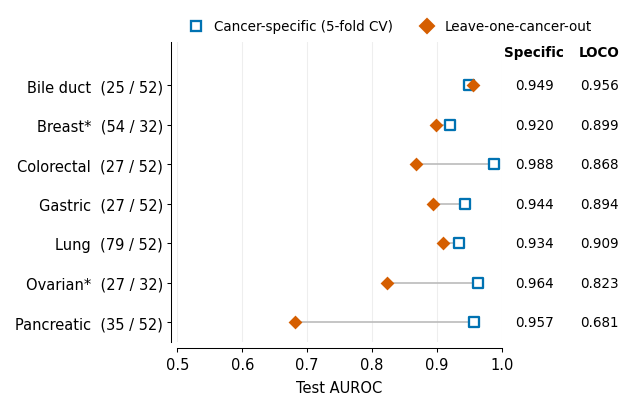

mean specific 0.951  mean LOCO 0.861


In [3]:
# ── Figure ─────────────────────────────────────────────────────────────────────
with plt.rc_context(PAPER_RC):
    fig, ax = plt.subplots(figsize=(4.6, 2.9))
    fig.subplots_adjust(left=0.27, right=0.74, bottom=0.17, top=0.86)
    y = np.arange(len(d))
    for yi, r in zip(y, d.itertuples()):
        ax.plot([r.spec_noCristiano_auc, r.noCristiano_auroc], [yi, yi], color="#BBBBBB", lw=0.8, zorder=1)
    ax.scatter(d.spec_noCristiano_auc, y, marker="s", s=22, facecolor="white", edgecolor=SPECIFIC,
               linewidth=1.1, zorder=3)
    ax.scatter(d.noCristiano_auroc, y, marker="D", s=22, color=LOCO, linewidth=0, zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{r.label}{'*' if r.label in FEMALE_ONLY else ''}  ({r.test_cases} / {r.test_controls})"
                        for r in d.itertuples()])
    ax.set_ylim(len(d) - 0.5, -1.1)        # a free row on top for the column headers
    ax.set_xlim(0.5, 1.0); ax.set_xticks(np.arange(0.5, 1.01, 0.1))
    ax.set_xlabel("Test AUROC")
    ax.grid(axis="x", color="#EEEEEE", lw=0.5, zorder=0); ax.set_axisbelow(True)
    ax.spines["left"].set_position(("outward", 3)); ax.spines["bottom"].set_position(("outward", 3))
    ax.tick_params(axis="both", which="both", length=2, pad=2)

    tr = mtransforms.blended_transform_factory(ax.transAxes, ax.transData)
    for x, head, col in ((1.10, "Specific", "spec_noCristiano_auc"), (1.30, "LOCO", "noCristiano_auroc")):
        ax.text(x, -0.85, head, transform=tr, ha="center", va="center", fontsize=6.5, fontweight="bold")
        for yi, v in zip(y, d[col]):
            ax.text(x, yi, f"{v:.3f}", transform=tr, ha="center", va="center", fontsize=6.5)
    handles = [Line2D([], [], ls="", marker="s", ms=4.5, mfc="white", mec=SPECIFIC, mew=1.1,
                      label="Cancer-specific (5-fold CV)"),
               Line2D([], [], ls="", marker="D", ms=4.5, color=LOCO, label="Leave-one-cancer-out")]
    ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0.0, 1.01), ncol=2, frameon=False,
              handletextpad=0.3, columnspacing=1.5, borderaxespad=0)
    savefig(fig, OUT, "cfdna_loco_nocristiano_specific_vs_loco",
            data=d[["cancer", "evaluation", "test_cases", "test_controls", "spec_noCristiano_auc",
                    "spec_noCristiano_ci_low", "spec_noCristiano_ci_high", "noCristiano_auroc",
                    "delta_loco_noCristiano_minus_spec_noCristiano"]])
    plt.show()
print("mean specific", round(d.spec_noCristiano_auc.mean(), 3), " mean LOCO", round(d.noCristiano_auroc.mean(), 3))